# DSCI 552 Homework 6

**Course:** DSCI 552, Machine Learning for Data Science (Fall 2026)

**Assignment:** Homework 6

**Name:** Zhonghao Yang

**USC ID:** 4643420428

**Github Username:** ZhonghaoYang-EDDIE

**Date:** November 6, 2026

**AI Assistance Disclosure:** AI assistance was used (Claude.ai, by Anthropic) in this assignment, mainly for explaining the problems, concepts and the datasets, helping fix package/environment issues and debugging code and syntax questions.

## 1. Tree-Based Methods

Import packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score

from imblearn.ensemble import BalancedRandomForestClassifier

from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

### (a) Download the APS Failure data

The first 20 lines of both csv files are license text, so the header starts on line 21. Missing values are marked as "na". The class is coded as 1 for pos and 0 for neg.

In [2]:
train = pd.read_csv('aps_failure_training_set.csv', skiprows=20, na_values='na')
test = pd.read_csv('aps_failure_test_set.csv', skiprows=20, na_values='na')

# class: pos -> 1, neg -> 0
y_train = (train.pop('class') == 'pos').astype(int)
y_test = (test.pop('class') == 'pos').astype(int)

print('train:', train.shape, '| test:', test.shape)
print('rows with NA - train:', train.isna().any(axis=1).sum(), '| test:', test.isna().any(axis=1).sum())

train: (60000, 170) | test: (16000, 170)
rows with NA - train: 59409 | test: 15835


### (b) Data Preparation

#### (i) Research what types of techniques are usually used
Common ways to handle missing data:
- Drop rows or columns with NAs. Not really an option here, since almost every row has at least one NA.
- Fill with the mean, median or mode of each feature. Simple and fast.
- KNN imputation: fill using the k most similar rows. Often better, but very slow on 60,000 rows and 170 features.
- Model-based / iterative imputation (e.g. MICE): predict each feature from the others. Most flexible and most expensive.
- Add a missing indicator column, usually together with one of the above.

I used median imputation. Most features are counters or histogram bins and are heavily right-skewed, so the median is more robust than the mean. Following the footnote, the training set is filled with training medians and the test set with test medians.

In [3]:
# train filled with train medians, test with test medians
X_train = train.fillna(train.median())
X_test = test.fillna(test.median())
print('NAs left - train:', X_train.isna().sum().sum(), '| test:', X_test.isna().sum().sum())

NAs left - train: 0 | test: 0


#### (ii) Calculate the coefficient of variation
CV = s / m for each of the 170 features, computed on the imputed training set. The full CV vector is stored in `cv` and sorted from high to low; only a summary, the top 13 and the 3 lowest are printed

In [4]:
cv = (X_train.std() / X_train.mean()).sort_values(ascending=False)

print(cv.describe().round(2).to_frame('CV').T)
print('\ntop 13:\n', cv.head(13).round(2).to_frame('CV').T)
print('lowest:', cv.tail(3).round(3).to_dict())

    count   mean   std  min  25%   50%    75%     max
CV  170.0  20.15  41.3  0.0  2.6  4.88  17.23  244.89

top 13:
     cf_000  co_000  ad_000  cs_009  dh_000  dj_000  ag_000  as_000  ay_009  \
CV  244.89  244.51  244.32  237.93  123.22  117.49   92.92   87.33   84.73   

    ak_000  az_009  ch_000  au_000  
CV   80.42   77.84   77.45   68.88  
lowest: {'bq_000': 0.719, 'br_000': 0.689, 'cd_000': 0.0}


#### (iii) Plot a correlation matrix


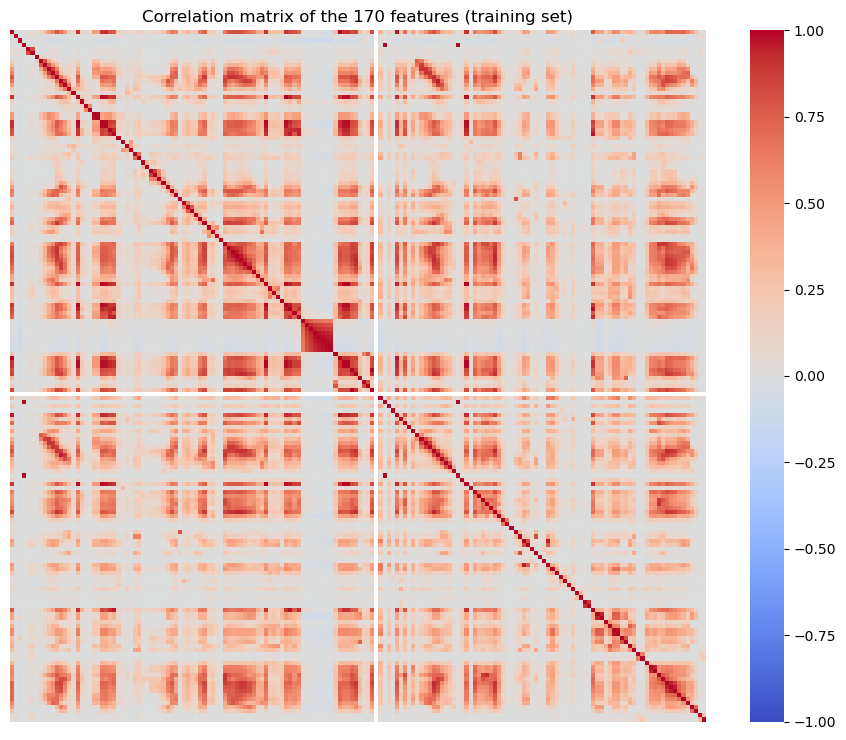

In [5]:
corr = X_train.corr()

plt.figure(figsize=(9, 7.5))
sns.heatmap(corr, cmap='coolwarm', vmin=-1, vmax=1, xticklabels=False, yticklabels=False)
plt.title('Correlation matrix of the 170 features (training set)')
plt.tight_layout()
plt.show()

Feature names are hidden since 170 labels wouldn't be readable. The white line is `cd_000`: it's constant, so its correlation is undefined (NaN).

#### (iv) Make scatter plots and box plots

c:\Users\15699\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


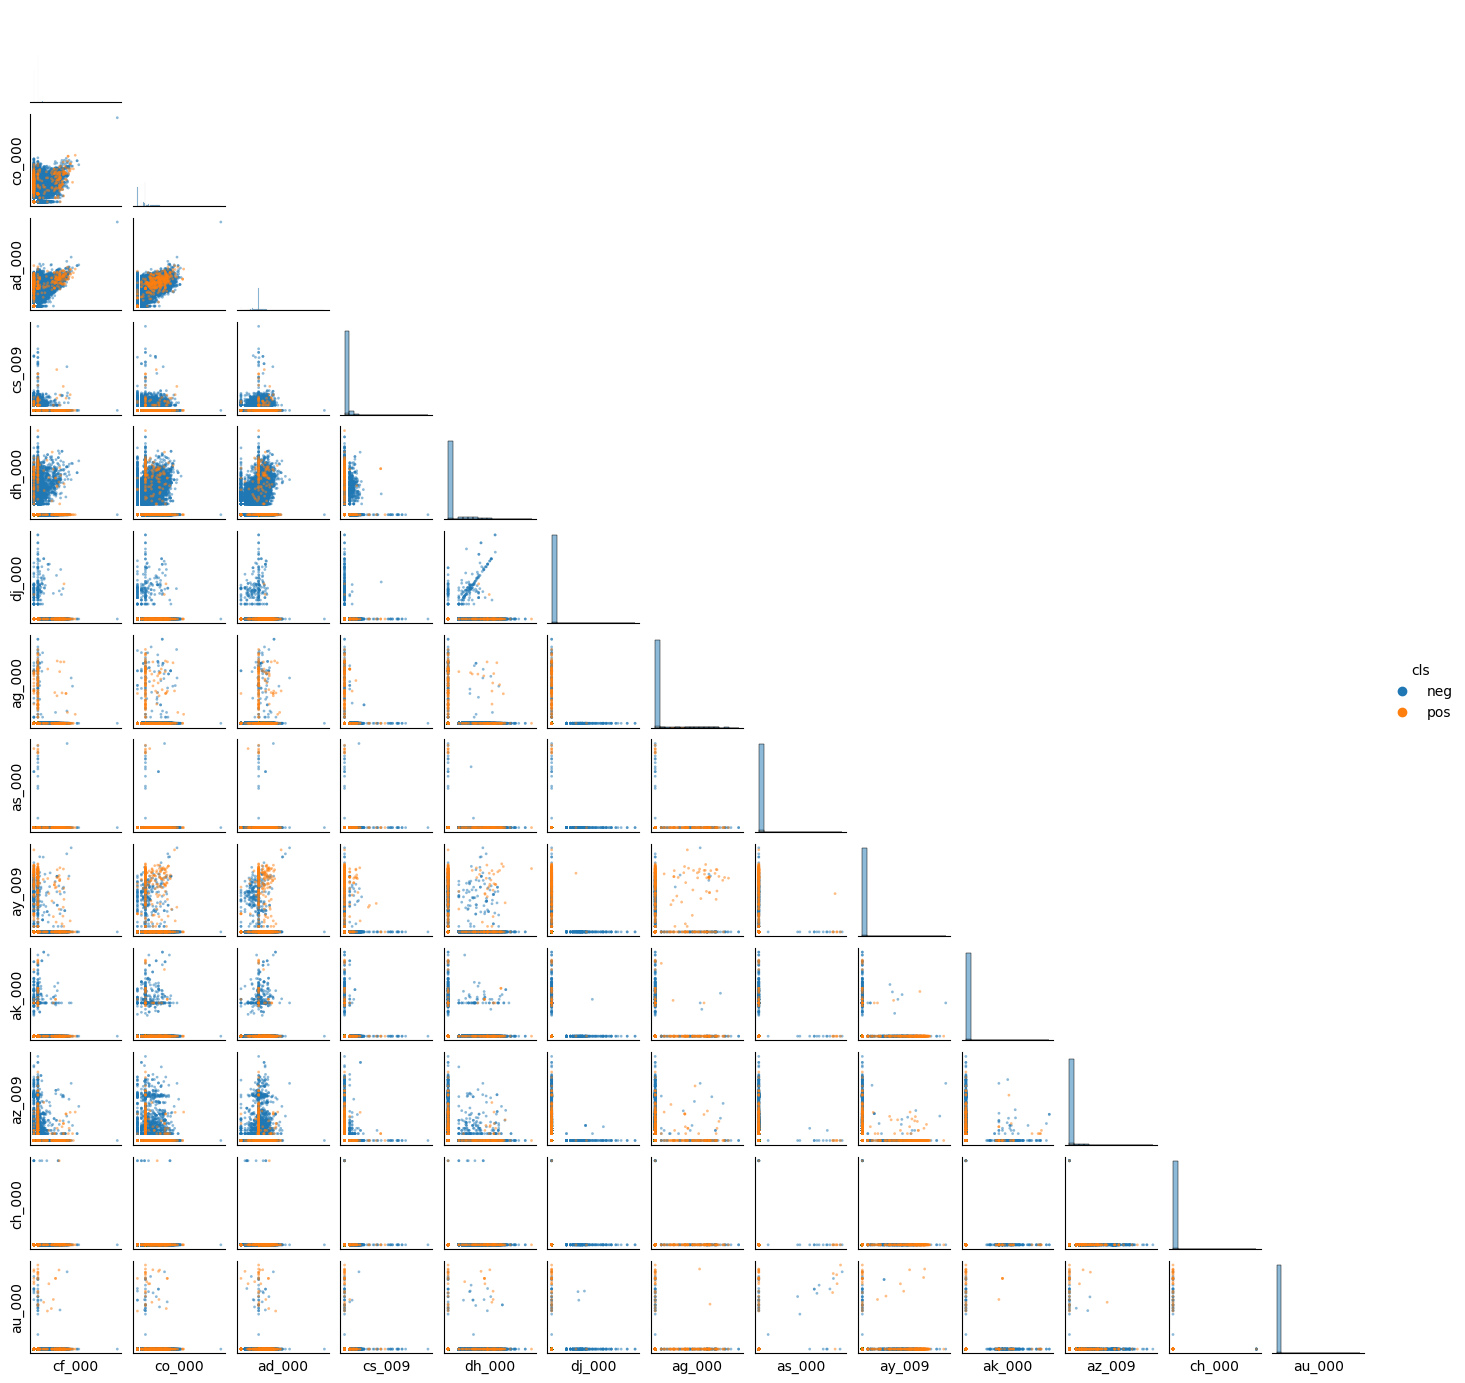

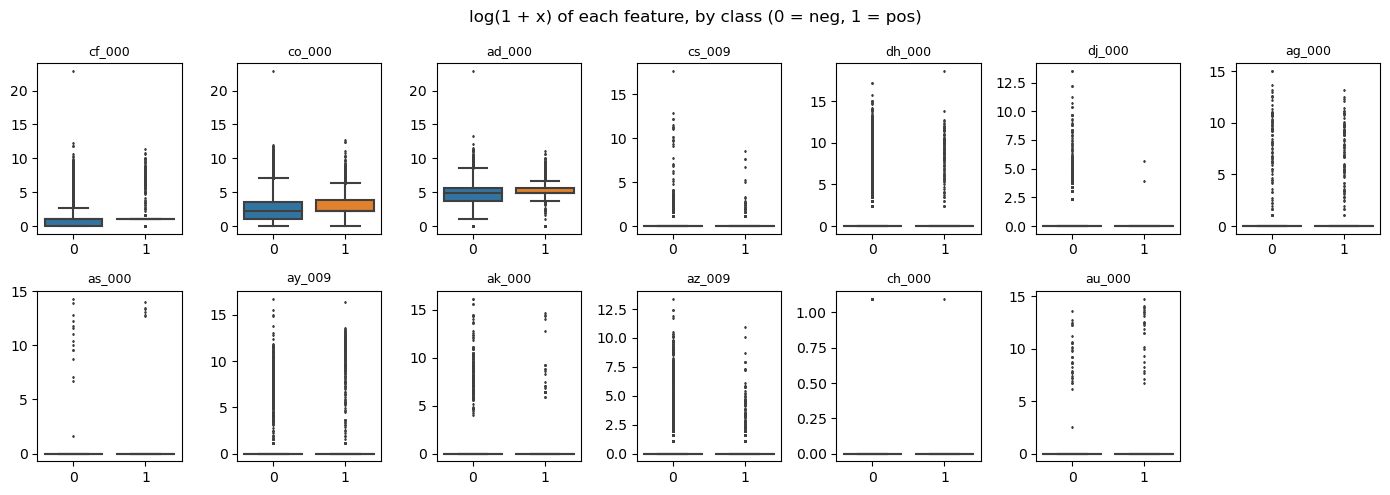

In [6]:
top = cv.head(13).index
logged = np.log1p(X_train[top])

# pairwise scatter plots, pos drawn on top of neg 
df = logged.assign(cls=y_train.map({0: 'neg', 1: 'pos'})).sort_values('cls')
g = sns.pairplot(df, hue='cls', corner=True, height=1.1, diag_kind='hist',
                 plot_kws={'s': 4, 'alpha': 0.5, 'linewidth': 0})
for ax in g.axes.flat:
    if ax:
        ax.set_xticks([]); ax.set_yticks([])
plt.show()

# box plots by class
fig, axes = plt.subplots(2, 7, figsize=(14, 5))
for ax, c in zip(axes.flat, top):
    sns.boxplot(x=y_train, y=logged[c], ax=ax, fliersize=1)
    ax.set_title(c, fontsize=9); ax.set_xlabel(''); ax.set_ylabel('')
axes.flat[-1].axis('off')
fig.suptitle('log(1 + x) of each feature, by class (0 = neg, 1 = pos)')
plt.tight_layout()
plt.show()

floor(sqrt(170)) = 13. The features are extremely right-skewed, so they're plotted on a log(1 + x) scale just for visualization.

**Can we tell which features are significant from the scatter plots alone?** 
Not really. The pos and neg points overlap a lot in every panel, and no pair of features clearly separates the two classes. Most of these 13 features are 0 for almost all trucks, so their high CV comes from a few huge values, not from being informative. The box plots look about the same for both classes too. At most, `ag_000`, `ay_009` and `au_000` seem to be nonzero a bit more often for pos trucks, but that's a guess, not significance.

#### (v) Is this data set imbalanced?

In [7]:
counts = pd.DataFrame({'train': y_train.value_counts(), 'test': y_test.value_counts()})
counts.index = ['neg', 'pos']
counts.loc['pos %'] = (counts.loc['pos'] / counts.sum() * 100).round(2)
print(counts)

          train      test
neg    59000.00  15625.00
pos     1000.00    375.00
pos %      1.67      2.34


Yes, it's heavily imbalanced. Only 1,000 of the 60,000 training rows (about 1.7%) are positive, so it's roughly 59 negatives for every positive. The test set looks similar (375 positives out of 16,000, about 2.3%). This means a model that always predicts "neg" would already get over 98% accuracy, so accuracy alone isn't a useful metric here.

### (c) Train a random forest

In [8]:
def evaluate(model, title, Xtr=X_train, ytr=y_train, Xte=X_test, yte=y_test):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    rows = {}
    for name, X, y, ax in [('train', Xtr, ytr, axes[0]), ('test', Xte, yte, axes[1])]:
        p = model.predict_proba(X)[:, 1]
        tn, fp, fn, tp = confusion_matrix(y, (p >= 0.5).astype(int)).ravel()
        rows[name] = {'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
                      'misclass': round((fp + fn) / len(y), 4), 'AUC': round(roc_auc_score(y, p), 4)}
        fpr, tpr, _ = roc_curve(y, p)
        ax.plot(fpr, tpr, label=f"AUC = {rows[name]['AUC']}")
        ax.plot([0, 1], [0, 1], 'k--', lw=0.8)
        ax.set(title=f'{title}: {name} ROC', xlabel='FPR', ylabel='TPR')
        ax.legend(loc='lower right')
    plt.tight_layout()
    plt.show()
    print(pd.DataFrame.from_dict(rows, orient='index'))
    return rows

# evaluate here will be reused in (c)-(f): confusion matrix, misclassification, AUC and ROC for train/test (0.5 threshold)


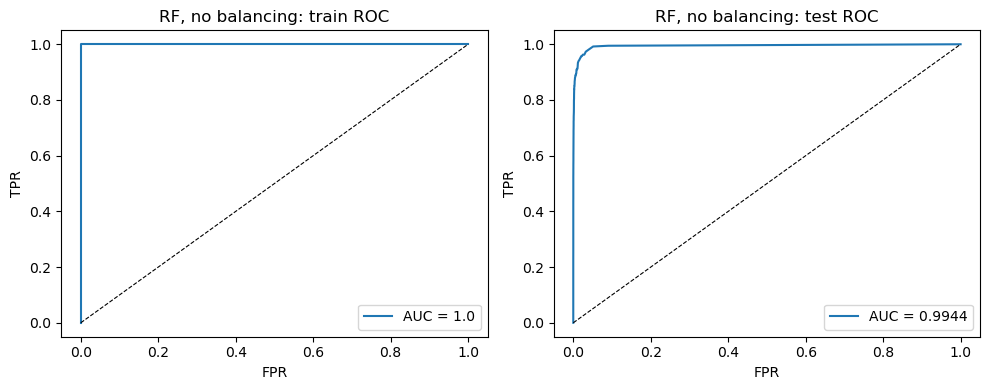

          TN  FP   FN    TP  misclass     AUC
train  59000   0    0  1000    0.0000  1.0000
test   15608  17  102   273    0.0074  0.9944

OOB error: 0.0062 | test error: 0.0074


In [9]:
# no class weights, no resampling 
rf = RandomForestClassifier(n_estimators=100, oob_score=True, n_jobs=-1, random_state=0)
rf.fit(X_train, y_train)

res_c = evaluate(rf, 'RF, no balancing')
print('\nOOB error:', round(1 - rf.oob_score_, 4), '| test error:', res_c['test']['misclass'])

The forest fits the training set perfectly (0 errors, AUC = 1), which is normal for a random forest since the trees are grown deep. That's why training error isn't useful here and OOB is the better estimate.

On the test set the misclassification rate is only 0.74% and AUC is 0.994, which looks great, but 102 of the 375 positive trucks are missed (recall around 73%). The low error mostly comes from the huge number of negatives being easy to get right.

OOB error (0.62%) is close to the test error (0.74%), so OOB is a decent estimate. It's a bit lower, probably partly because the test set has a higher share of positives (2.3% vs 1.7%), and positives are where most mistakes happen.

### (d) Research class imbalance in random forest

Common ways to handle class imbalance in random forests:
- **Weighted random forest**: give the minority class a bigger weight in the split criterion and in the leaf votes (`class_weight` in sklearn).
- **Balanced random forest** (Chen, Liaw & Breiman, 2004): each tree is trained on a bootstrap sample where the majority class is undersampled to the same size as the minority class.
- **Resampling the whole training set** before fitting, e.g. random over/undersampling or SMOTE.
- **Threshold moving**: keep the model as is but lower the 0.5 cutoff for predicting pos.

I first tried `class_weight='balanced_subsample'`, but it barely changed anything (it was actually a bit worse). The trees are grown until the leaves are pure, so the weights hardly affect the final votes. So I went with a **balanced random forest**, which balances the classes inside every tree's bootstrap sample.

c:\Users\15699\anaconda3\Lib\site-packages\imblearn\ensemble\_forest.py:825: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


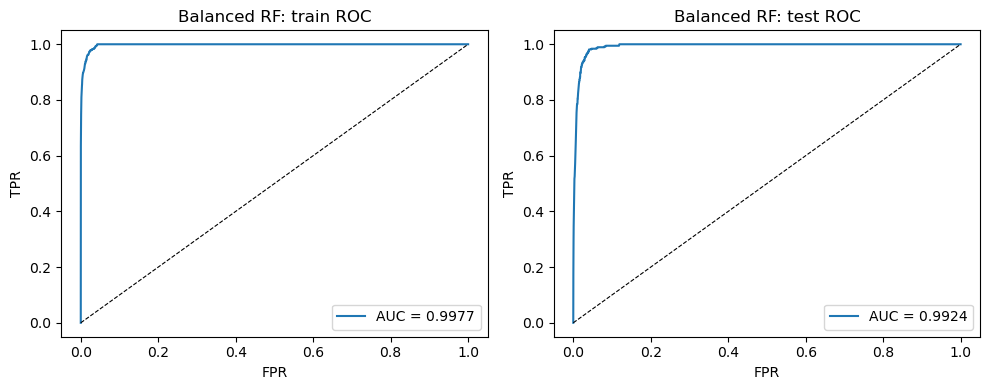

          TN    FP  FN    TP  misclass     AUC
train  55746  3254   0  1000    0.0542  0.9977
test   14810   815   6   369    0.0513  0.9924

OOB error: 0.0533 | test error: 0.0513


In [10]:
# 500 trees so that most negatives get enough out-of-bag predictions
brf = BalancedRandomForestClassifier(n_estimators=500, sampling_strategy='auto', replacement=False,
                                     bootstrap=True, oob_score=True, n_jobs=-1, random_state=0)
brf.fit(X_train, y_train)

res_d = evaluate(brf, 'Balanced RF')
print('\nOOB error:', round(1 - brf.oob_score_, 4), '| test error:', res_d['test']['misclass'])

Compared with (c):
- The balanced forest catches almost all the failing trucks: only 6 of 375 positives are missed on the test set, vs 102 before (recall goes from about 73% to 98%).
- The price is more false alarms (815 vs 17), so the overall misclassification rate goes up from 0.74% to 5.1%. But here missing a faulty truck is way more expensive than an extra check (500 vs 10 in the Scania cost metric), so this trade-off is clearly worth it. Total cost on the test set drops from about 51,170 to 11,150.
- AUC stays basically the same (0.994 vs 0.992), so the ranking of trucks by risk didn't really change. What changed is where the model puts the cutoff.
- The training set is no longer fit perfectly, since each tree only sees a small balanced subset of the negatives.
- OOB error (5.3%) is close to the test error (5.1%). I used 500 trees because each tree only uses about 1,000 of the 59,000 negatives, so a negative rarely ends up out-of-bag. With 100 trees about half of them had no OOB prediction at all and the OOB error was way too optimistic (3.3%). The warning above means a few still have none even with 500 trees, but it's a small fraction now.

### (e) XGBoost and Model Trees

In [11]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
xgb = XGBClassifier(n_estimators=200, tree_method='hist', n_jobs=-1, random_state=0)
alphas = {'reg_alpha': [0, 0.01, 0.1, 1, 10, 100]}

gs_e = GridSearchCV(xgb, alphas, scoring={'f1': 'f1', 'acc': 'accuracy'}, refit='f1', cv=skf)
gs_e.fit(X_train, y_train)

cv_e = pd.DataFrame(gs_e.cv_results_).set_index('param_reg_alpha')[['mean_test_f1', 'mean_test_acc']]
cv_e['cv_error'] = 1 - cv_e['mean_test_acc']
print(cv_e.drop(columns='mean_test_acc').round(4).T)
print('\nbest alpha:', gs_e.best_params_['reg_alpha'])

param_reg_alpha  0.00    0.01    0.10    1.00    10.00   100.00
mean_test_f1     0.8075  0.8105  0.8163  0.7923  0.7498  0.6266
cv_error         0.0060  0.0059  0.0057  0.0064  0.0077  0.0113

best alpha: 0.1


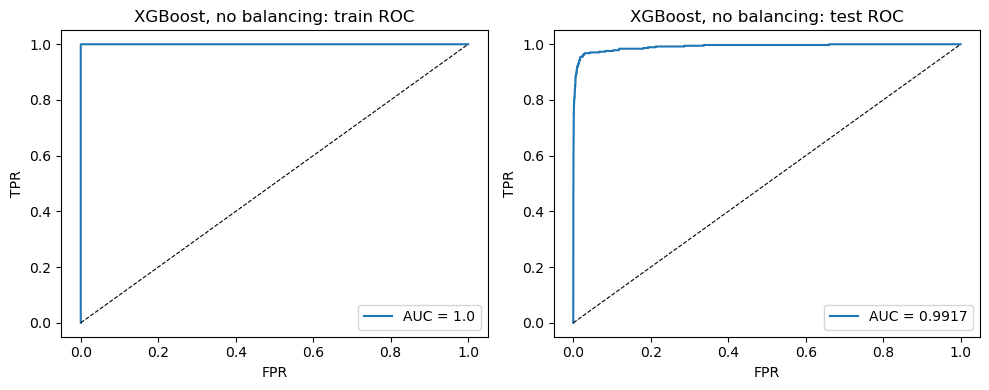

          TN  FP  FN    TP  misclass     AUC
train  59000   0   0  1000    0.0000  1.0000
test   15605  20  95   280    0.0072  0.9917

5-fold CV error: 0.0057 | test error: 0.0072


In [12]:
res_e = evaluate(gs_e.best_estimator_, 'XGBoost, no balancing')
print('\n5-fold CV error:', round(cv_e.loc[gs_e.best_params_['reg_alpha'], 'cv_error'], 4),
      '| test error:', res_e['test']['misclass'])

Per Piazza @142, standard XGBoost with L1 regularization (`reg_alpha`) is used instead of a logistic regression model tree. α is chosen by stratified 5-fold CV with F1 as the score (lecture notes, Lesson 4 p. 34–35), since accuracy isn't meaningful on such imbalanced data.

CV picks α = 0.1, but F1 is pretty flat for small α and only drops a lot at 10 and 100. The CV error (0.57%) is a bit lower than the test error (0.72%), partly because the test set has more positives (2.3% vs 1.7%) and partly because picking α by the best CV score is slightly optimistic. Training error is 0 again, so it's not useful.

Compared with the random forest in (c), XGBoost is about the same: 95 missed positives vs 102, 20 false alarms vs 17, AUC 0.992 vs 0.994. It still misses about a quarter of the failing trucks since nothing was done about the imbalance.

### (f) Use SMOTE to pre-process your data

In [13]:
pipe = Pipeline([('smote', SMOTE(random_state=0)),
                 ('xgb', XGBClassifier(n_estimators=200, tree_method='hist', n_jobs=-1, random_state=0))])

gs_f = GridSearchCV(pipe, {'xgb__reg_alpha': alphas['reg_alpha']},
                    scoring={'f1': 'f1', 'acc': 'accuracy'}, refit='f1', cv=skf)
gs_f.fit(X_train, y_train)

cv_f = pd.DataFrame(gs_f.cv_results_).set_index('param_xgb__reg_alpha')[['mean_test_f1', 'mean_test_acc']]
cv_f['cv_error'] = 1 - cv_f['mean_test_acc']
print(cv_f.drop(columns='mean_test_acc').round(4).T)
print('\nbest alpha:', gs_f.best_params_['xgb__reg_alpha'])

param_xgb__reg_alpha  0.00    0.01    0.10    1.00    10.00   100.00
mean_test_f1          0.8246   0.822  0.8204  0.8171  0.7827  0.6230
cv_error              0.0059   0.006  0.0060  0.0062  0.0078  0.0179

best alpha: 0


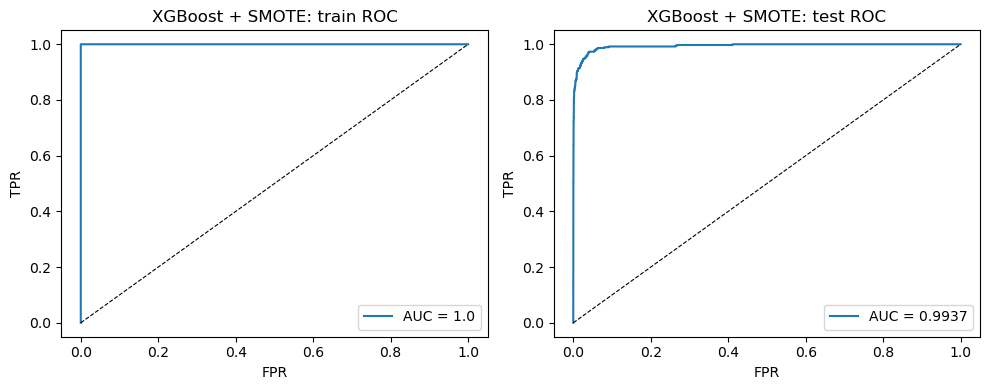

          TN  FP  FN    TP  misclass     AUC
train  59000   0   0  1000    0.0000  1.0000
test   15562  63  58   317    0.0076  0.9937

5-fold CV error: 0.0059 | test error: 0.0076


In [14]:
res_f = evaluate(gs_f.best_estimator_, 'XGBoost + SMOTE')
print('\n5-fold CV error:', round(cv_f.loc[gs_f.best_params_['xgb__reg_alpha'], 'cv_error'], 4),
      '| test error:', res_f['test']['misclass'])

SMOTE is done inside each CV fold through an imblearn `Pipeline`, so synthetic points never leak into the validation fold. Doing SMOTE before CV would be the wrong way and would make the CV score too optimistic.

CV picks α = 0, so L1 doesn't really help here. The CV error (0.59%) is a bit lower than the test error (0.76%), same as in (e).

Compared with (e), SMOTE misses fewer failing trucks (58 vs 95, recall 75% → 85%) but gives more false alarms (63 vs 20), so the misclassification rate is about the same and AUC is slightly higher (0.994 vs 0.992). With the Scania cost metric, the test cost drops from 47,700 to 29,630, so SMOTE clearly helps. It's still worse than the balanced random forest in (d), though (6 missed, cost 11,150).

## 2. ISLR 6.6.3

This is the lasso written as a constraint. At s = 0 all the β's are forced to 0, so the model just predicts the mean of y. As s grows, the constraint loosens and the model gets more flexible, until s is big enough that we're back to plain least squares.

**(a) Training RSS: iv. Steadily decrease.** A bigger s means the β's have more room to fit the training data, so the training RSS can only go down (or stay the same), until it reaches the least squares RSS.

**(b) Test RSS: ii. Decrease initially, then increase in a U shape.** At first the model gets less biased and fits the real signal better, so test RSS drops. After some point it starts overfitting the noise and test RSS goes back up.

**(c) Variance: iii. Steadily increase.** At s = 0 the model is just a constant, so variance is basically 0. As s grows the model gets more flexible and depends more on the particular training set, so variance keeps going up.

**(d) Squared bias: iv. Steadily decrease.** The more flexible the model, the closer it can get to the true relationship, so bias keeps going down.

**(e) Irreducible error: v. Remain constant.** It comes from the noise ε, not from the model, so changing s does nothing to it.

## 3. ISLR 6.6.5

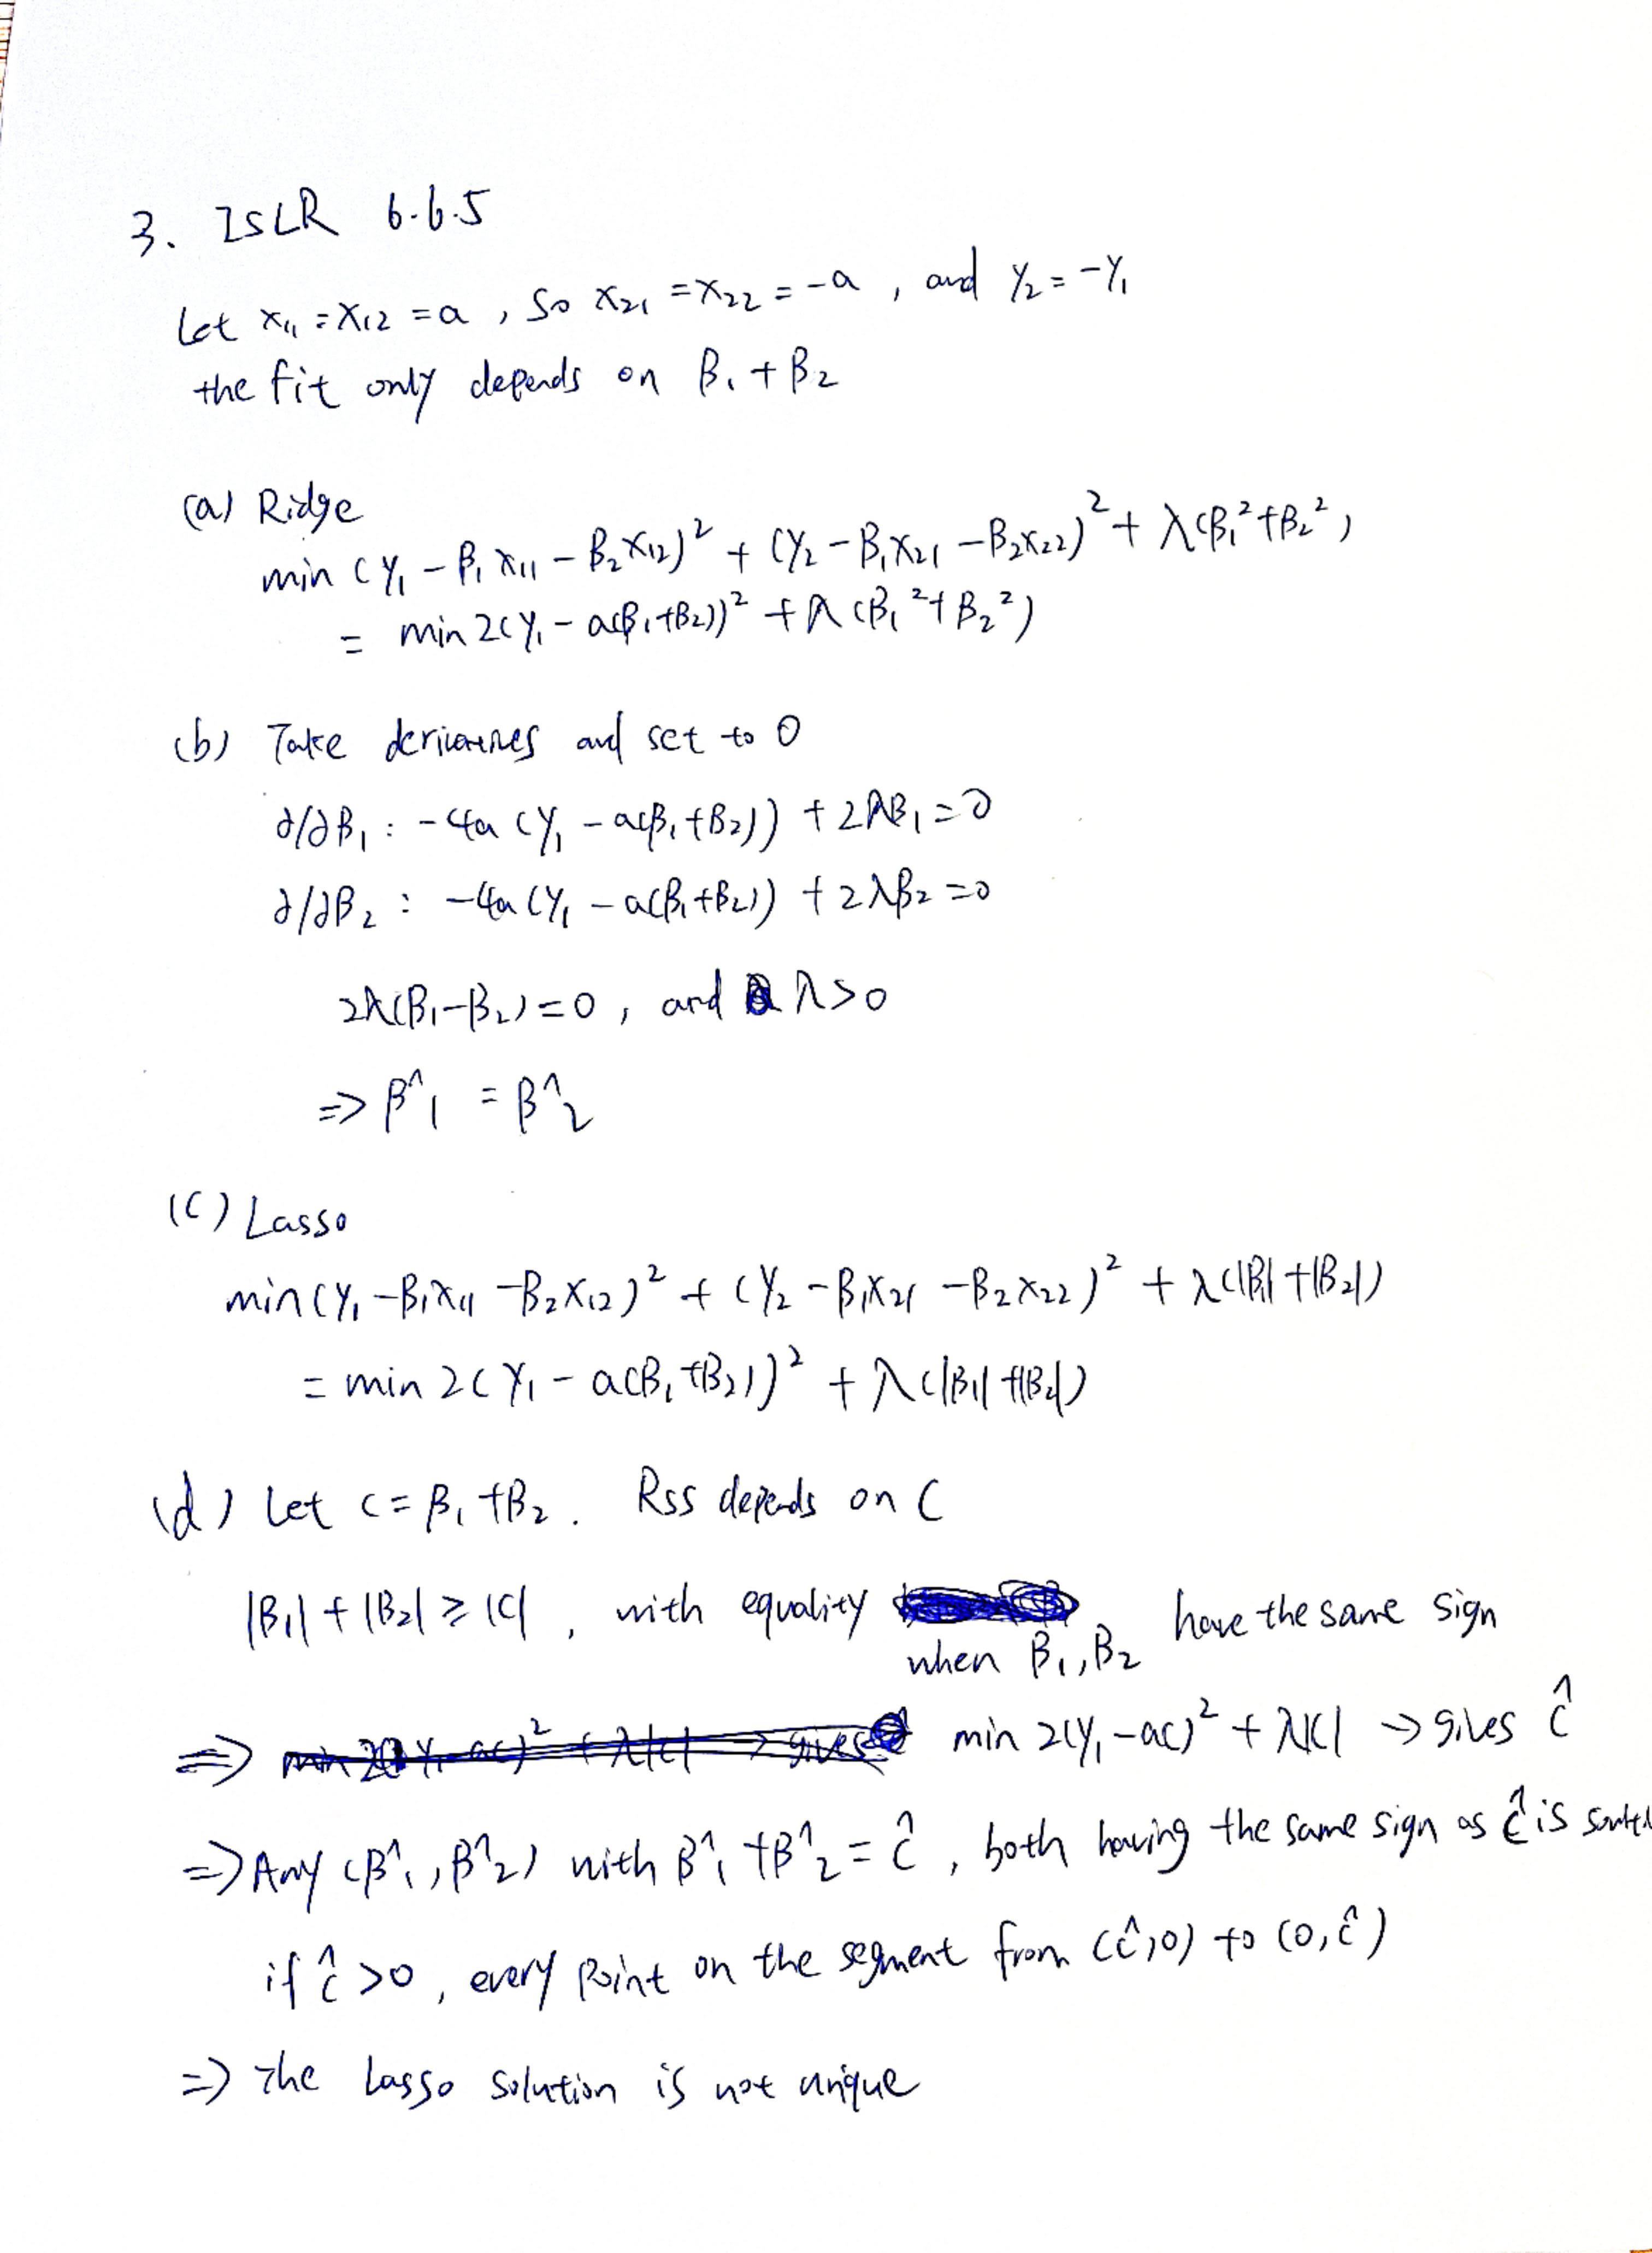

## 4. ISLR 8.4.5

The 10 estimates of P(Red | X): 0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7, 0.75.

**Majority vote:** 6 of the 10 estimates are above 0.5 (0.55, 0.6, 0.6, 0.65, 0.7, 0.75), so 6 trees vote Red and 4 vote Green. Final class: **Red**.

**Average probability:** (0.1 + 0.15 + 0.2 + 0.2 + 0.55 + 0.6 + 0.6 + 0.65 + 0.7 + 0.75) / 10 = 4.5 / 10 = 0.45 < 0.5. Final class: **Green**.

So the two approaches give different answers here. The majority vote only counts how many trees lean Red, while the average also takes into account how confident they are: the 4 Green votes are pretty confident (0.1 to 0.2), while the Red votes are mostly just over 0.5.

## 5. ISLR 9.7.3

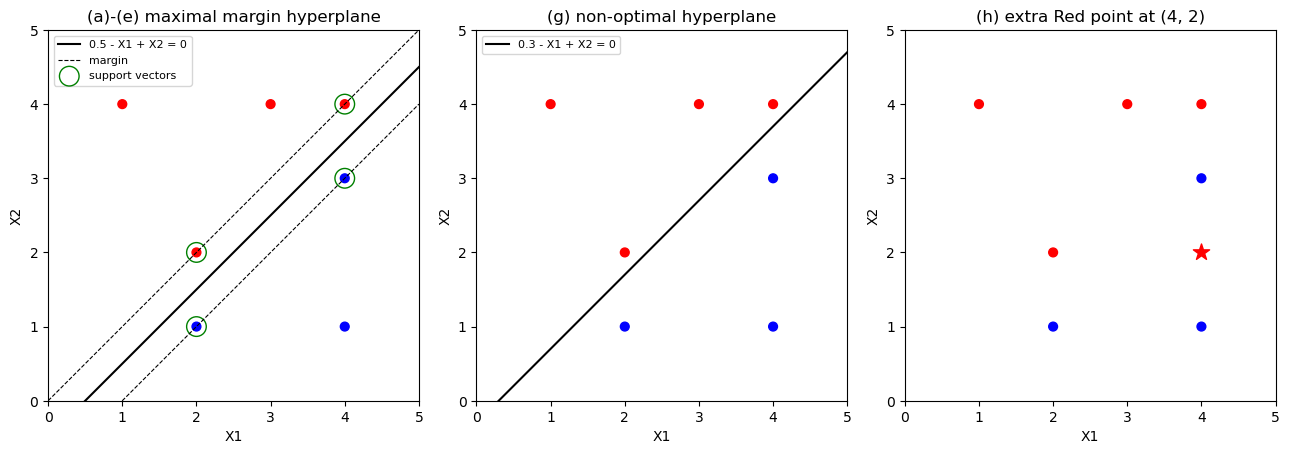

In [15]:
X = np.array([[3, 4], [2, 2], [4, 4], [1, 4], [2, 1], [4, 3], [4, 1]])
y = np.array(['Red'] * 4 + ['Blue'] * 3)
x = np.linspace(0, 5, 2)

def base(ax, title):
    ax.scatter(X[:, 0], X[:, 1], c=y, s=40)
    ax.set(xlim=(0, 5), ylim=(0, 5), xlabel='X1', ylabel='X2', title=title, aspect='equal')

fig, axes = plt.subplots(1, 3, figsize=(13, 4.3))

# (a)-(e): hyperplane, margins and support vectors
base(axes[0], '(a)-(e) maximal margin hyperplane')
axes[0].plot(x, x - 0.5, 'k', label='0.5 - X1 + X2 = 0')
axes[0].plot(x, x, 'k--', lw=0.8, label='margin')
axes[0].plot(x, x - 1, 'k--', lw=0.8)
sv = X[[1, 2, 4, 5]]
axes[0].scatter(sv[:, 0], sv[:, 1], s=200, facecolors='none', edgecolors='g', label='support vectors')
axes[0].legend(loc='upper left', fontsize=8)

# (g): separates the classes but isn't optimal
base(axes[1], '(g) non-optimal hyperplane')
axes[1].plot(x, x - 0.3, 'k', label='0.3 - X1 + X2 = 0')
axes[1].legend(loc='upper left', fontsize=8)

# (h): extra Red point at (4, 2)
base(axes[2], '(h) extra Red point at (4, 2)')
axes[2].scatter(4, 2, c='red', marker='*', s=150)

plt.tight_layout()
plt.show()

**(a)** See the first plot.

**(b)** The optimal separating hyperplane goes halfway between the closest Red and Blue points, (2, 2)/(2, 1) and (4, 4)/(4, 3). So it passes through (2, 1.5) and (4, 3.5): X2 = X1 − 0.5, i.e. **0.5 − X1 + X2 = 0**.

**(c)** Classify to Red if 0.5 − X1 + X2 > 0, and to Blue otherwise. So β0 = 0.5, β1 = −1, β2 = 1.

**(d)** The margin is bounded by the dashed lines X2 = X1 and X2 = X1 − 1. Its width (distance from the hyperplane to either dashed line) is 0.5 / √2 ≈ 0.35.

**(e)** The support vectors are (2, 2) and (4, 4) for Red, and (2, 1) and (4, 3) for Blue (circled in green).

**(f)** Observation 7 is (4, 1). It's not a support vector and sits well outside the margin, so moving it a little doesn't change anything. The hyperplane only depends on the support vectors, as long as the point doesn't move into the margin.

**(g)** For example 0.3 − X1 + X2 = 0 (second plot). It still separates the two classes, but it's closer to the Red points than to the Blue ones, so its margin is smaller than the optimal one.

**(h)** Adding a Red point at (4, 2) (third plot): it sits right between the Blue points (4, 1) and (4, 3), so no straight line can put it on the Red side without also misclassifying a Blue point.